# Premium MACD before zero

ST/pivots improve forecast quality; a cross forecast is not a profitable early-entry policy. Read FINDINGS.md and the frozen PLAN.md for source, execution and multiple-testing limits.

In [1]:
from pathlib import Path
import pandas as pd, json, numpy as np
import matplotlib.pyplot as plt
ROOT=Path('/Users/ramachandran/MACD-mini-ADV/research/precross_supertrend_pivots_20261003')
h=pd.read_csv(ROOT/'behavior_and_event_returns.csv').query('period == "holdout"')
b=pd.read_csv(ROOT/'book_results.csv')
names={'turn': 'MACD turn', 'closed_st': 'Completed premium ST', 'preview_st': 'Forming premium ST', 'above_p': 'Above daily P', 'reclaim_p': 'Recent P reclaim', 'preview_st_p': 'Forming ST + above P', 'preview_st_room': 'Forming ST + pivot room', 'underlying_context': 'Premium ST + underlying context', 'cross5': 'Cross + 5 min', 'cross1': 'Cross + 1 min'}
h[['rule','trials','cross_30_pct','cross_by_close_pct','early_fills','early_timeouts','median_timely_lead_minutes','mean_pair_delta_pct_per_trial']]

,rule,trials,cross_30_pct,cross_by_close_pct,early_fills,early_timeouts,median_timely_lead_minutes,mean_pair_delta_pct_per_trial
8,turn,1371,24.872356,61.415026,1338,934,13.0,-0.983065
9,closed_st,494,39.878543,77.327935,465,280,11.0,-1.151950
10,preview_st,785,36.560510,75.414013,759,454,12.0,-0.188251
11,above_p,1117,28.469114,68.128917,1084,720,13.0,-0.959070
12,reclaim_p,324,12.962963,45.679012,321,252,12.5,-1.193159
13,preview_st_p,705,38.439716,78.014184,679,396,12.0,-0.134730
14,preview_st_room,620,37.741935,77.258065,600,353,12.0,-0.617531
15,underlying_context,446,39.461883,77.578475,428,244,12.0,-2.380994


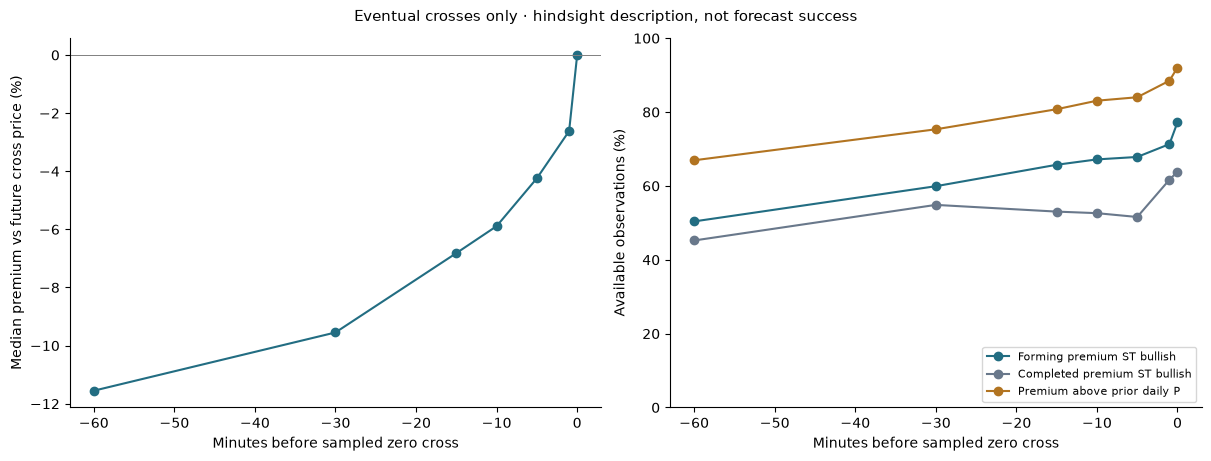

In [2]:
a=pd.read_csv(ROOT/'cross_aligned_summary.csv').query('period == "holdout" and offset_minutes <= 0')
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
axes[0].plot(a.offset_minutes,a.median_premium_vs_cross_pct,marker='o',color='#226d82')
axes[0].axhline(0,color='grey',lw=.7);axes[0].set_ylabel('Median premium vs future cross price (%)')
for col,label,color in [('preview_st_bull_pct','Forming premium ST bullish','#226d82'),('closed_st_bull_pct','Completed premium ST bullish','#69788b'),('above_p_pct','Premium above prior daily P','#b27421')]:axes[1].plot(a.offset_minutes,a[col],marker='o',label=label,color=color)
axes[1].set_ylabel('Available observations (%)');axes[1].set_ylim(0,100);axes[1].legend(fontsize=8,loc='lower right')
for ax in axes:ax.set_xlabel('Minutes before sampled zero cross');ax.spines[['top','right']].set_visible(False)
fig.suptitle('Eventual crosses only · hindsight description, not forecast success',fontsize=11)
fig.savefig(ROOT/'cross_path.png',dpi=150,bbox_inches='tight');plt.show()

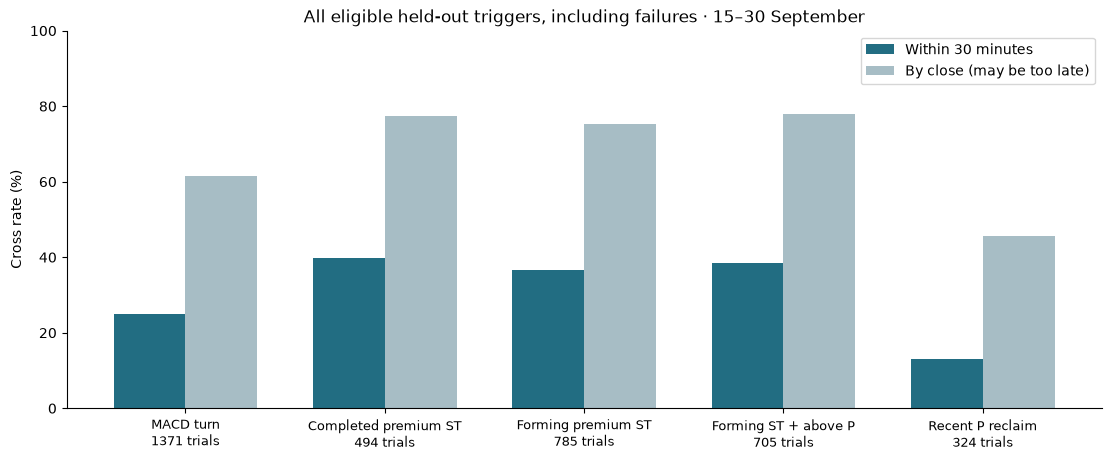

In [3]:
rules=['turn','closed_st','preview_st','preview_st_p','reclaim_p']
z=h.set_index('rule').loc[rules];x=np.arange(len(z))
fig,ax=plt.subplots(figsize=(11,4.5),layout='constrained')
ax.bar(x-.18,z.cross_30_pct,width=.36,label='Within 30 minutes',color='#226d82')
ax.bar(x+.18,z.cross_by_close_pct,width=.36,label='By close (may be too late)',color='#a7bdc5')
ax.set_xticks(x,[names[r]+'\n'+str(int(z.loc[r,'trials']))+' trials' for r in rules],fontsize=9)
ax.set_ylim(0,100);ax.set_ylabel('Cross rate (%)');ax.legend();ax.spines[['top','right']].set_visible(False)
ax.set_title('All eligible held-out triggers, including failures · 15–30 September')
fig.savefig(ROOT/'cross_forecast.png',dpi=150,bbox_inches='tight');plt.show()

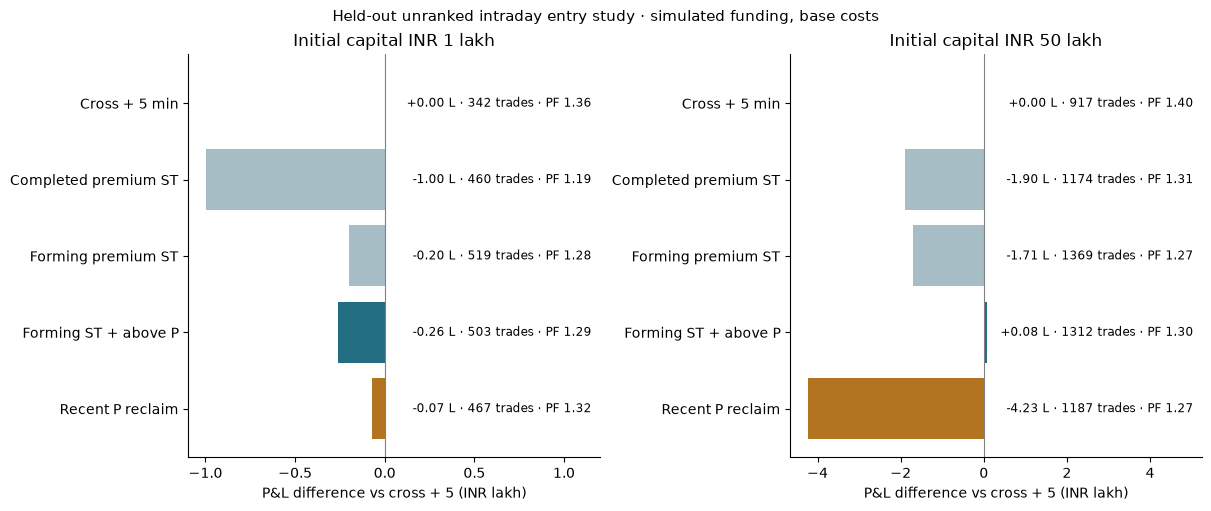

,capital,rule,new_trades,early_trades,closed_win_pct,closed_pf,marked_pnl,delta_pnl
1,100000,cross5,342,0,42.105263,1.362698,2.087929e+05,0.000000e+00
6,100000,cross1,340,0,42.941176,1.247889,7.536150e+04,-1.334314e+05
11,100000,turn,631,411,38.510301,1.290506,1.236890e+05,-8.510388e+04
16,100000,closed_st,460,152,40.869565,1.189375,1.092766e+05,-9.951625e+04
21,100000,preview_st,519,249,42.003854,1.281851,1.886629e+05,-2.012992e+04
26,100000,above_p,565,315,40.707965,1.324591,1.581273e+05,-5.066552e+04
31,100000,reclaim_p,467,140,40.685225,1.319190,2.018084e+05,-6.984468e+03
36,100000,preview_st_p,503,220,40.556660,1.289974,1.829168e+05,-2.587607e+04
41,100000,preview_st_room,474,185,41.350211,1.254290,1.248029e+05,-8.398995e+04
46,100000,underlying_context,473,168,41.437632,1.167233,8.915780e+04,-1.196351e+05


In [4]:
z=b.query('period == "holdout" and extra_bps == 0 and timeout == 30')
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
rules=['cross5','closed_st','preview_st','preview_st_p','reclaim_p']
for ax,cap in zip(axes,[100000,5000000]):
    s=z[z.capital==cap].set_index('rule').loc[rules];vals=s.delta_pnl.to_numpy()/1e5
    ax.barh([names[r] for r in rules],vals,color=['#69788b','#a7bdc5','#a7bdc5','#226d82','#b27421']);ax.invert_yaxis();ax.axvline(0,color='grey',lw=.8)
    for i,(v,n,pf) in enumerate(zip(vals,s.new_trades,s.closed_pf)):ax.text(.98,i,f'{v:+.2f} L · {int(n)} trades · PF {pf:.2f}',transform=ax.get_yaxis_transform(),ha='right',va='center',fontsize=8.5)
    ax.set_xlim(min(vals)-.1*max(1,np.ptp(vals)),max(vals)+1.2*max(1,np.ptp(vals)));ax.set_xlabel('P&L difference vs cross + 5 (INR lakh)');ax.set_title(f'Initial capital INR {cap/1e5:g} lakh');ax.spines[['top','right']].set_visible(False)
fig.suptitle('Held-out unranked intraday entry study · simulated funding, base costs',fontsize=11)
fig.savefig(ROOT/'book_quality.png',dpi=150,bbox_inches='tight');plt.show()
z[['capital','rule','new_trades','early_trades','closed_win_pct','closed_pf','marked_pnl','delta_pnl']]

In [5]:
v=json.loads((ROOT/'VALIDATION.json').read_text())
assert v['checks_passed']==10
assert all(x['cash_reconciles'] and x['no_negative_cash'] and x['no_pyramids_or_oversells'] for x in v['book_checks'].values())
assert v['source_preservation']['old_ledger_unchanged']
pd.read_csv(ROOT/'holdout_tests.csv')

,rule,control,sessions,mean_daily_difference,t,p,difference_total,p_holm_17
0,turn,cross5,12,-148690.309156,-2.184577,0.051453,-1.784284e+06,0.823245
1,closed_st,cross5,12,-15809.212319,-0.705561,0.495132,-1.897105e+05,1.000000
2,preview_st,cross5,12,-14245.017233,-0.274475,0.788806,-1.709402e+05,1.000000
3,above_p,cross5,12,-89002.315106,-1.546963,0.150143,-1.068028e+06,1.000000
4,reclaim_p,cross5,12,-35221.639144,-1.139859,0.278557,-4.226597e+05,1.000000
5,preview_st_p,cross5,12,645.430913,0.013522,0.989453,7.745171e+03,1.000000
6,preview_st_room,cross5,12,-11438.184577,-0.249492,0.807578,-1.372582e+05,1.000000
7,underlying_context,cross5,12,-50705.998921,-1.778326,0.102967,-6.084720e+05,1.000000
8,turn,cross1,12,-114963.428940,-1.734377,0.110747,-1.379561e+06,1.000000
9,closed_st,cross1,12,17917.667898,0.475579,0.643679,2.150120e+05,1.000000
